# Example of the `aitlas` toolbox in the context of image classification

This notebook shows a sample implementation of a land cover classification using the `aitlas` toolbox and the SustainBench: Representation Learning for Land Cover Classification dataset.

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import LLCCDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader
import matplotlib.pyplot as plt
import numpy as np

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/land_cover_representation/tiles",
    "csv_file": "./data/land_cover_representation/metadata.csv",
    "selection" : "triplets"
}
dataset = LLCCDataset(dataset_config)
print(dataset.__len__())

100000


## Show images from the dataset

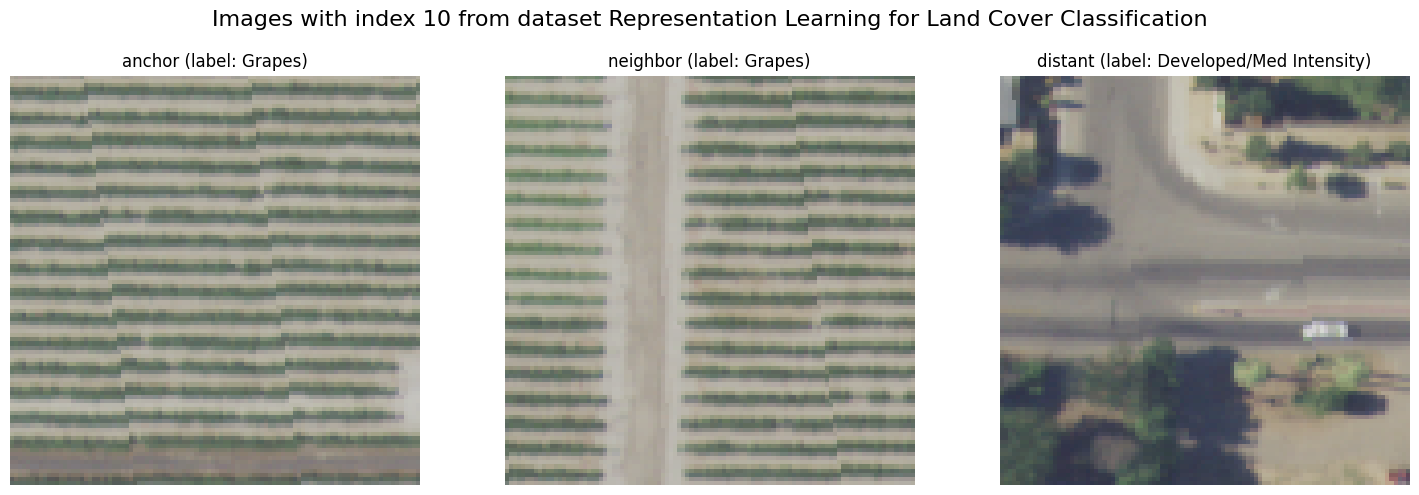

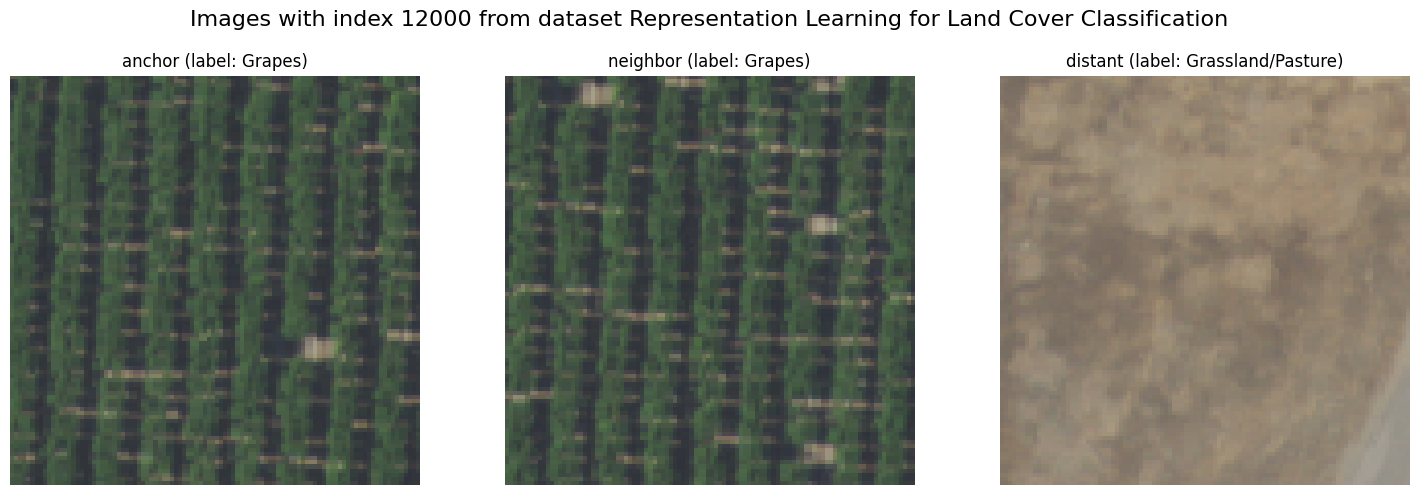

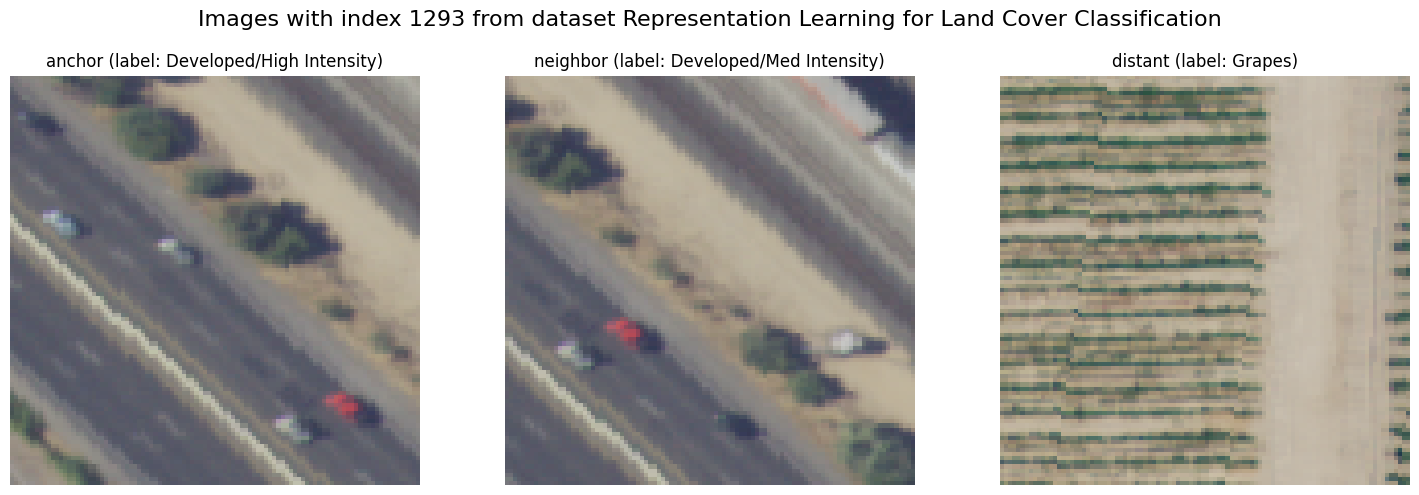

In [11]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(12000)
fig3 = dataset.show_image(1293)

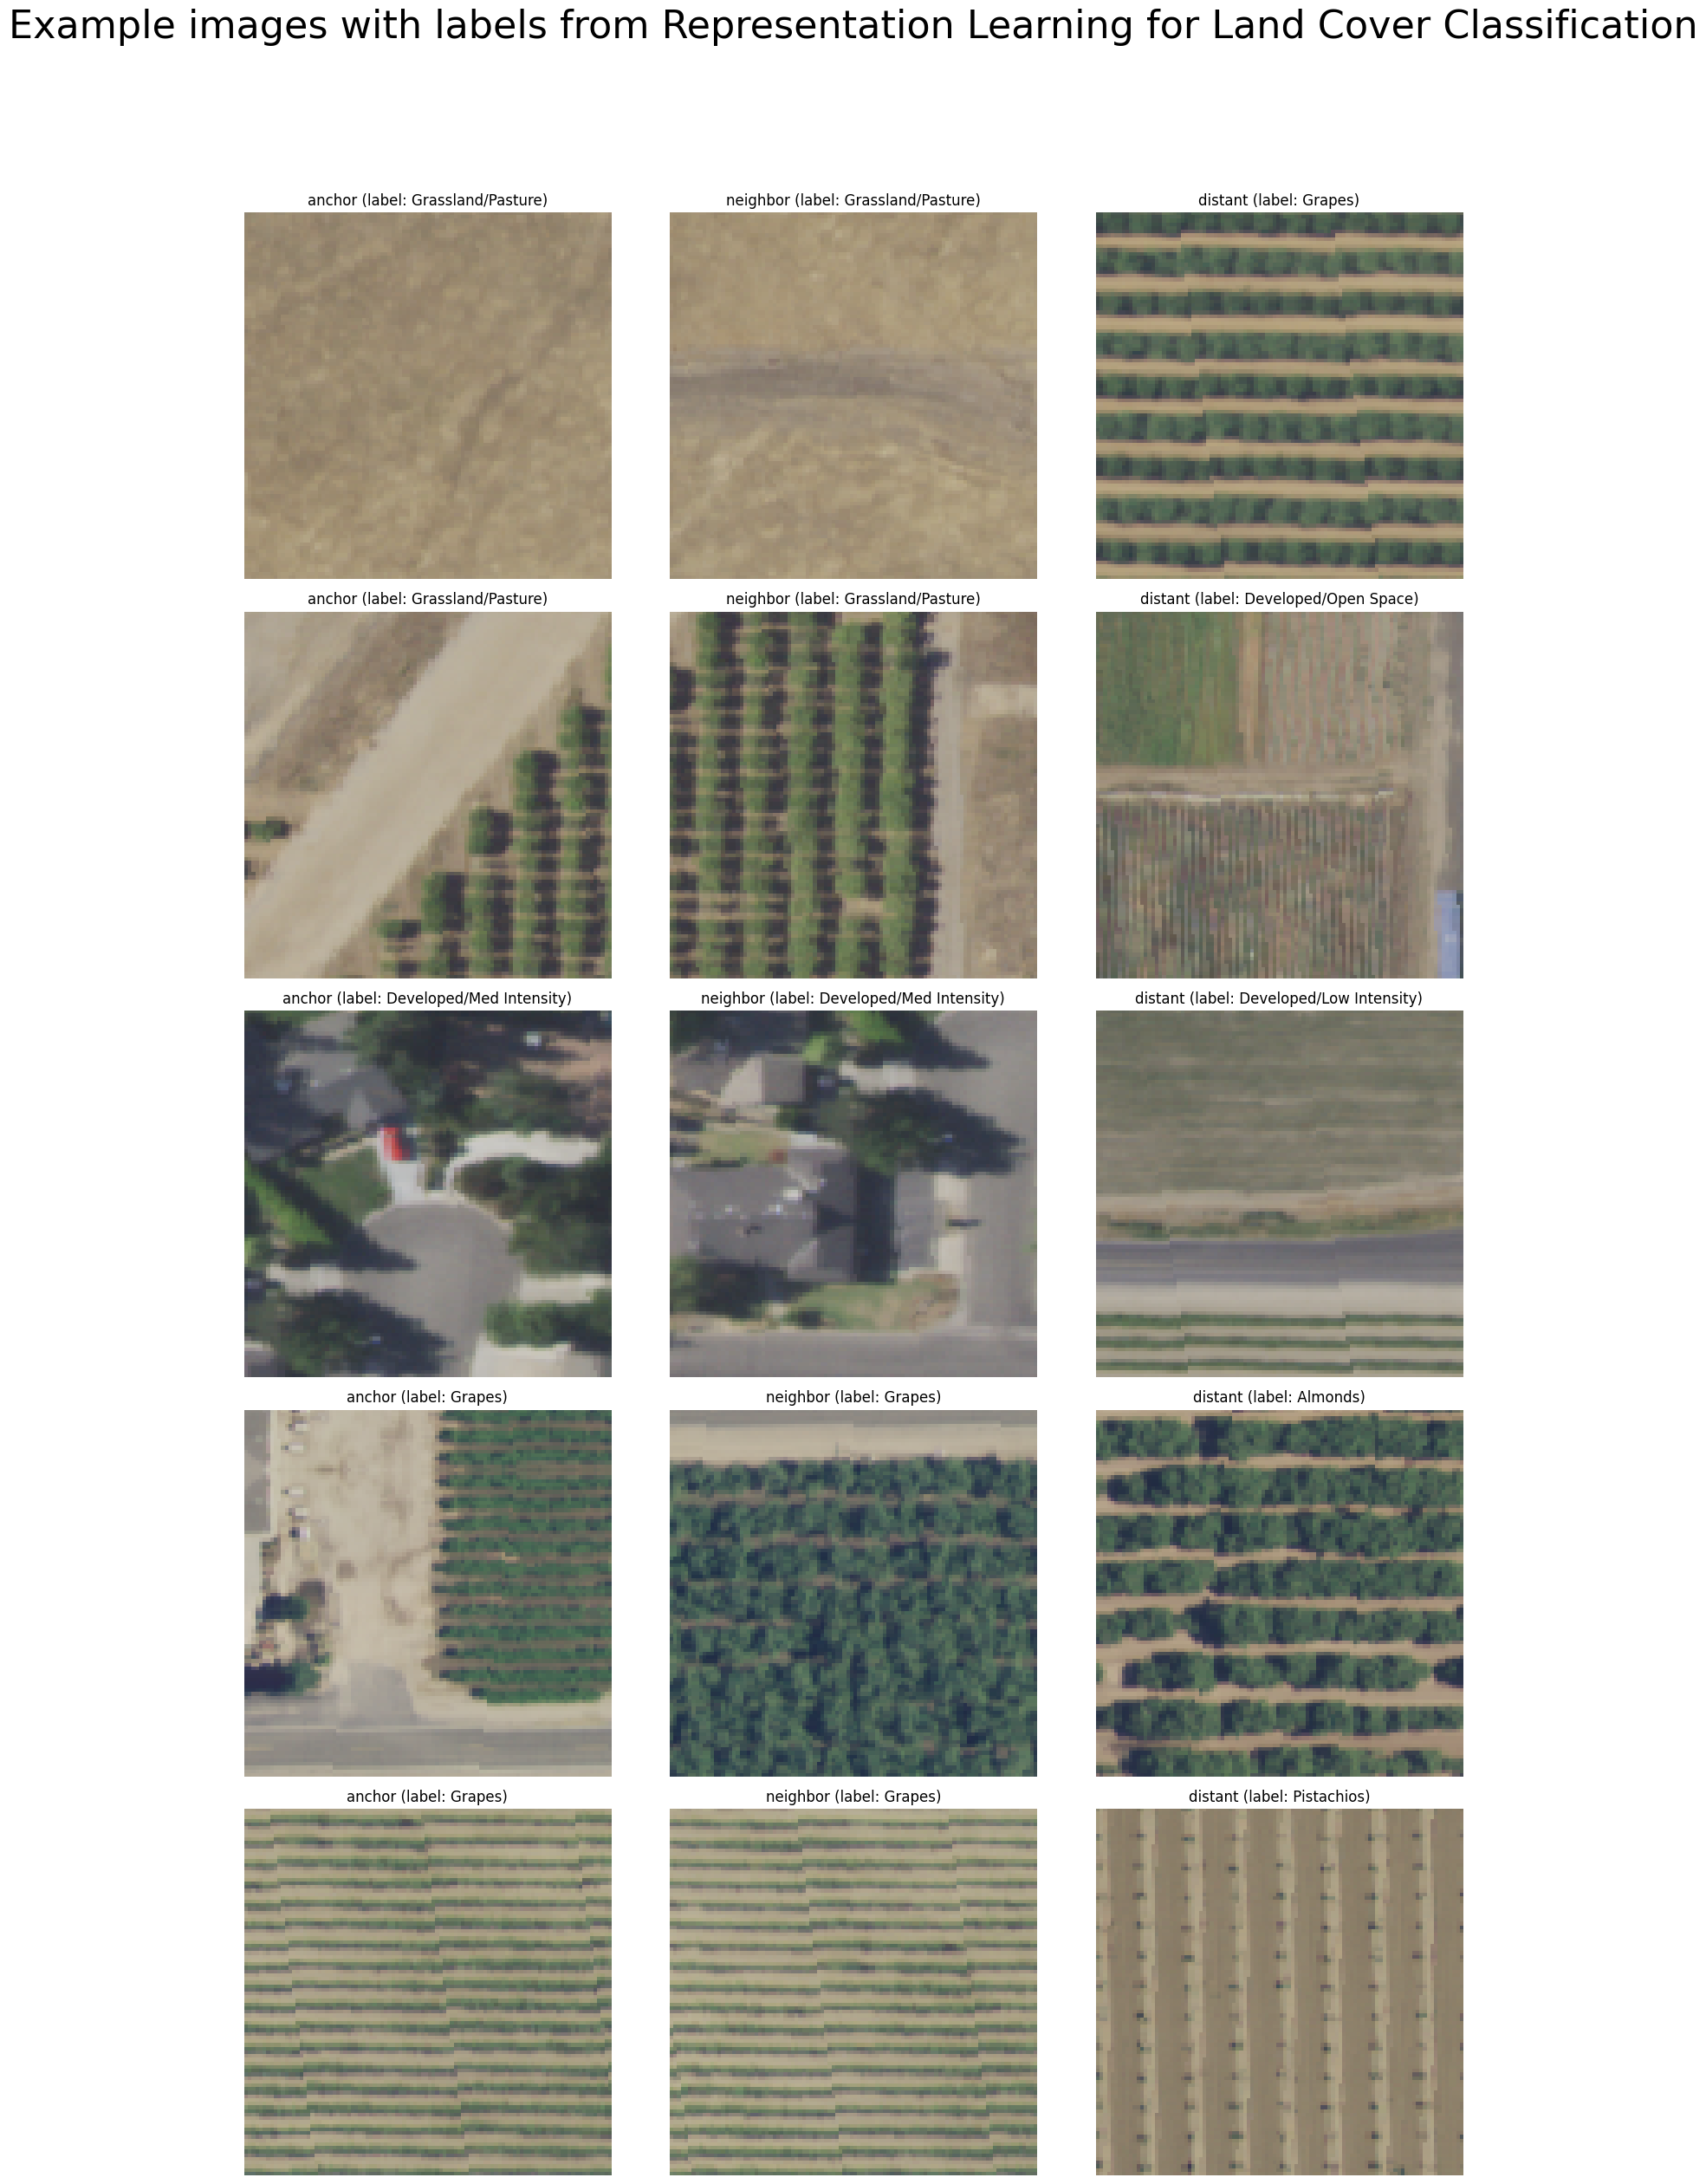

In [12]:
fig3 = dataset.show_batch(5)

## Inspect the data

In [13]:
dataset.show_samples()

,Anchor_File,Anchor_Label,Neighbor_File,Neighbor_Label,Distant_File,Distant_Label
0,0anchor,Fallow/Idle Cropland,0neighbor,Fallow/Idle Cropland,0distant,Grassland/Pasture
1,1anchor,Grassland/Pasture,1neighbor,Grassland/Pasture,1distant,Grapes
2,2anchor,Grapes,2neighbor,Grapes,2distant,Developed/High Intensity
3,3anchor,Grapes,3neighbor,Grapes,3distant,Grassland/Pasture
4,4anchor,Grapes,4neighbor,Grapes,4distant,Grassland/Pasture
5,5anchor,Developed/Med Intensity,5neighbor,Developed/Low Intensity,5distant,Barren
6,6anchor,Alfalfa,6neighbor,Alfalfa,6distant,Grapes
7,7anchor,Grapes,7neighbor,Grapes,7distant,Grassland/Pasture
8,8anchor,Almonds,8neighbor,Almonds,8distant,Grapes
9,9anchor,Developed/High Intensity,9neighbor,Developed/High Intensity,9distant,Grapes


In [17]:
dataset.data_distribution_table()

,Label,Count
0,Fallow/Idle Cropland,18897
1,Grassland/Pasture,42771
2,Grapes,90484
3,Developed/High Intensity,4273
4,Developed/Med Intensity,16955
...,...,...
56,Rice,1
57,Rye,1
58,Other Crops,2
59,Watermelons,1


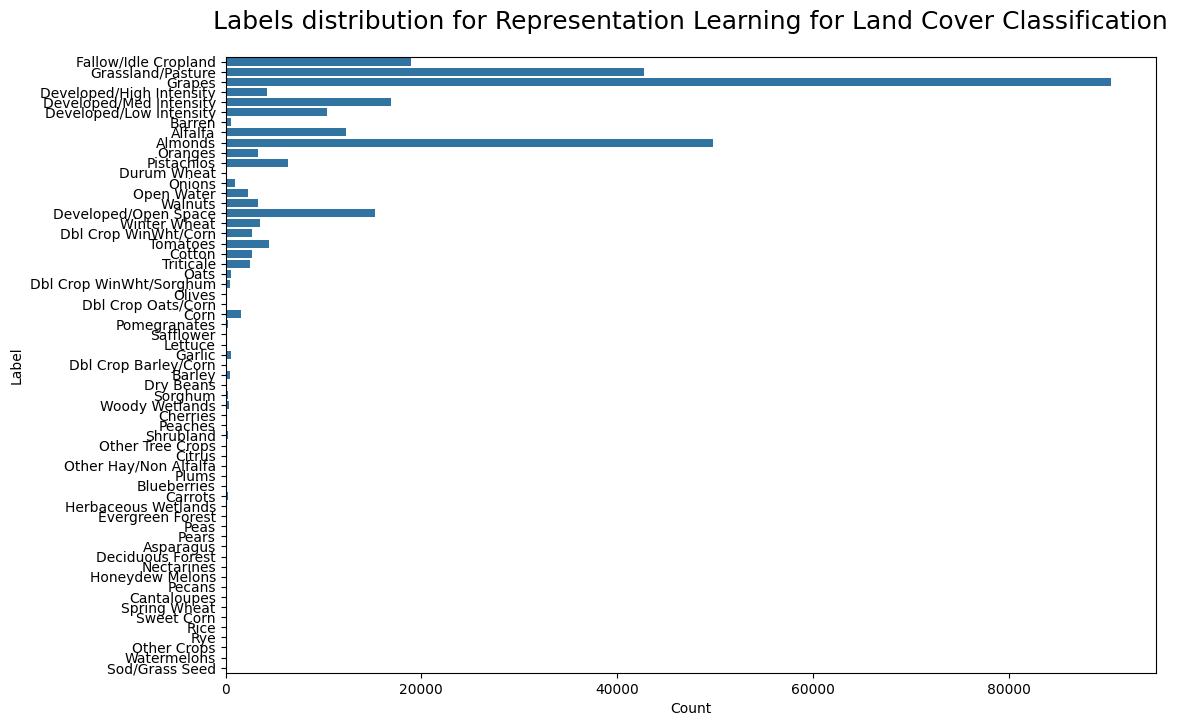

In [18]:
fig = dataset.data_distribution_barchart()

## Load train split

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/land_cover_representation/tiles",
    "csv_file": "./data/land_cover_representation/metadata.csv",
    "selection" : "individual",
    "task" : "train"
}

train_dataset = LLCCDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/land_cover_representation/tiles",
    "csv_file": "./data/land_cover_representation/metadata.csv",
    "selection" : "individual",
    "task" : "val",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = LLCCDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(216735, 41352)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/land_cover_representation"
model_config = {
    "num_classes": 61, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-09-02 06:57:57,836 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-09-02 06:57:58,021 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [8]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-09-02 06:57:58,070 INFO Starting training.
training: 100%|██████████| 6773/6773 [28:06<00:00,  4.02it/s]
2025-09-02 07:26:04,673 INFO epoch: 1, time: 1686, loss:  1.14580
testing on train set: 100%|██████████| 6773/6773 [09:47<00:00, 11.53it/s]
2025-09-02 07:35:54,848 INFO Accuracy:0.6884305718965557, Precision Micro:0.6884305718965557, Precision Macro:0.2593455296419858, Precision Weighted:0.6707259613614664, Precision per Class:[0.33386076 0.6499362  0.         0.29166667 0.         0.
 0.         0.         0.52195946 0.         0.         0.
 0.67617579 0.         0.         0.         0.         0.50237718
 0.         0.81732852 0.         0.46222136 0.         0.
 0.75902993 0.         0.         0.         0.79667778 0.55305692
 0.         0.75167038 0.45101597 0.45090145 0.67518301 0.69197178
 0.19911504 0.         0.         0.         0.66929818 0.
 0.         0.58604207 0.68453608 0.         0.         0.69458128
 0.         0.         0.48972189 0.         0.94117647 0

0.6417682728206481

## Predictions

2025-09-02 13:52:10,981 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/land_cover_representation/checkpoint.pth.tar
2025-09-02 13:52:11,236 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/land_cover_representation/checkpoint.pth.tar at epoch 11


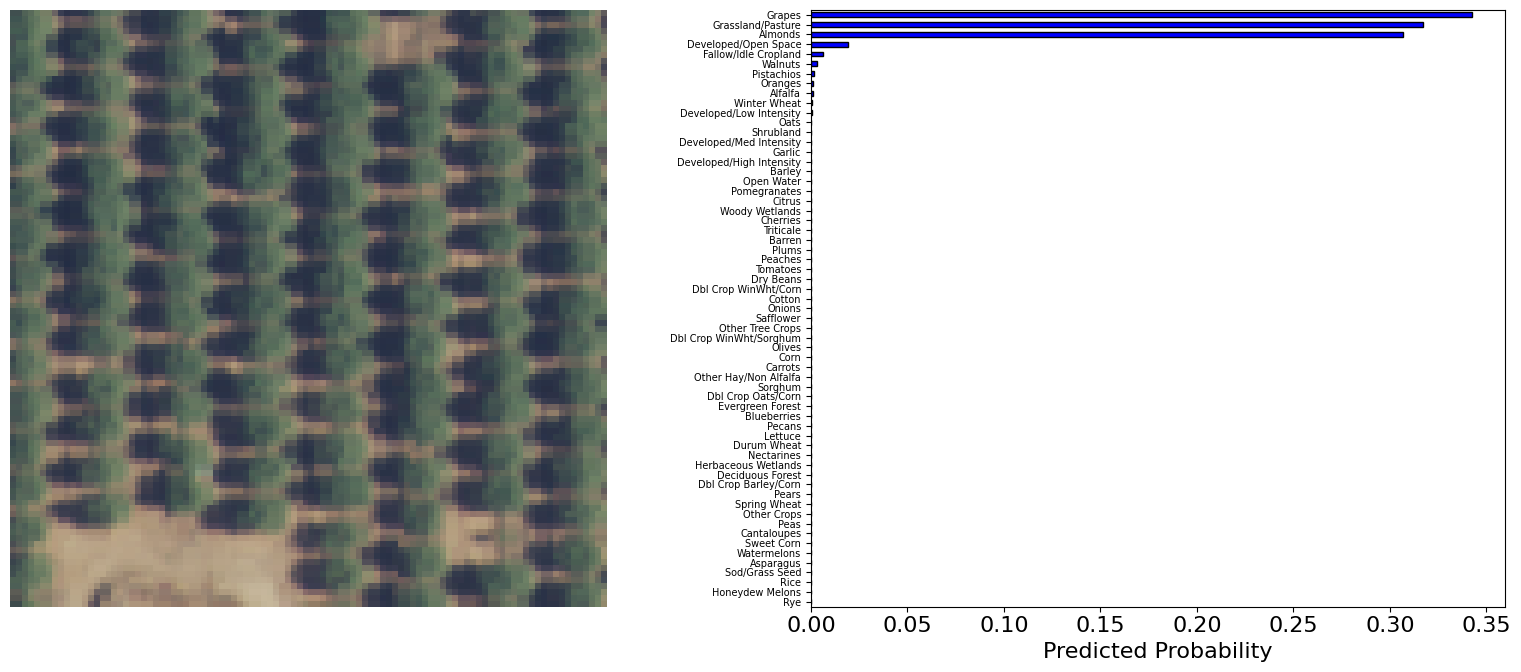

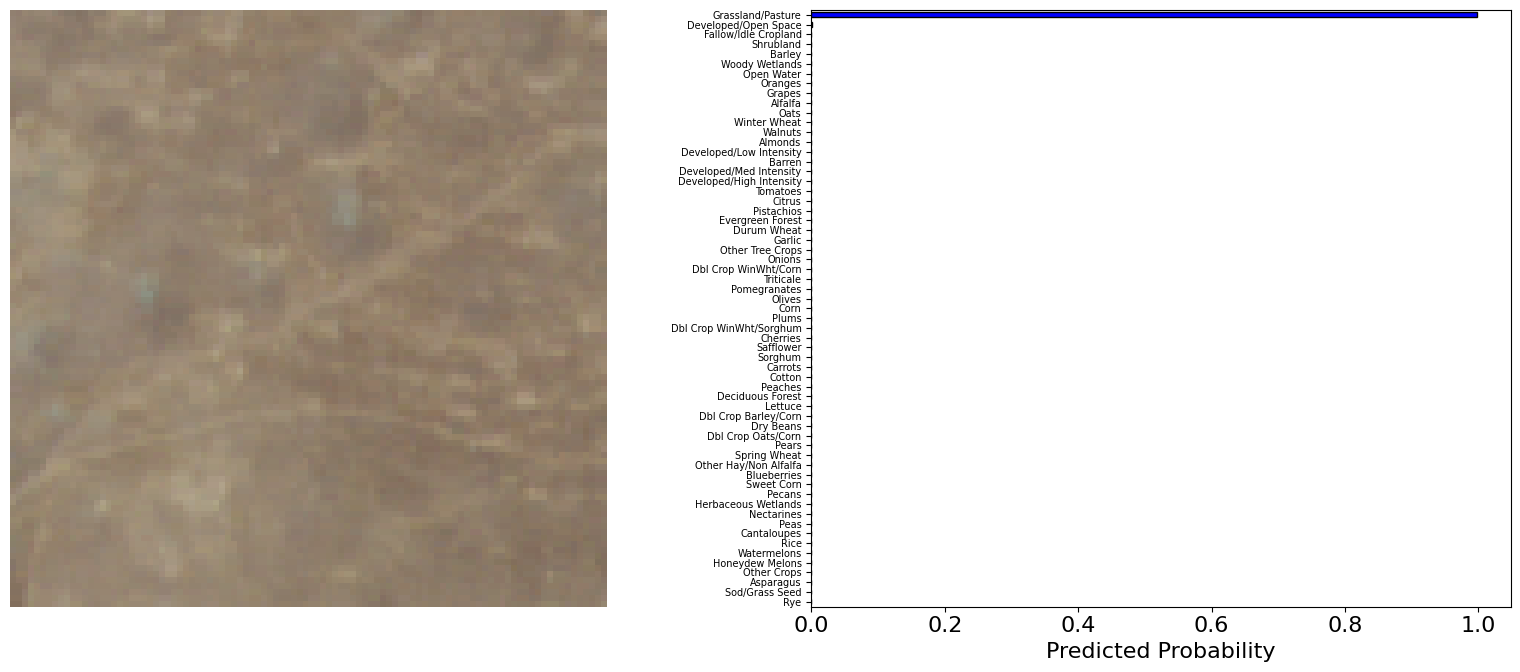

In [ ]:
labels = ["Corn","Cotton","Rice","Sorghum","Sweet Corn","Barley","Durum Wheat","Spring Wheat","Winter Wheat","Rye","Oats","Safflower",
        "Alfalfa","Other Hay/Non Alfalfa","Dry Beans","Other Crops","Watermelons","Onions","Peas","Tomatoes","Sod/Grass Seed",
        "Fallow/Idle Cropland", "Cherries","Peaches","Grapes","Other Tree Crops","Citrus","Pecans","Almonds","Walnuts","Pears",
        "Open Water","Developed/Open Space","Developed/Low Intensity","Developed/Med Intensity","Developed/High Intensity","Barren",
        "Deciduous Forest","Evergreen Forest","Shrubland","Grassland/Pasture","Woody Wetlands","Herbaceous Wetlands","Pistachios",
        "Triticale","Carrots","Asparagus","Garlic","Cantaloupes","Olives","Oranges","Honeydew Melons","Pomegranates","Nectarines",
        "Plums","Dbl Crop WinWht/Corn","Dbl Crop Oats/Corn","Lettuce","Dbl Crop WinWht/Sorghum","Dbl Crop Barley/Corn","Blueberries"]
plt.rcParams.update({'font.size': 5})
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/land_cover_representation/checkpoint.pth.tar"
model.load_model(model_path)

image = np.load('./data/land_cover_representation/tiles/13distant.npy')[:, :, :3]
fig = model.predict_image(image, labels, transform)
# update text size
for ax in fig.axes:
    for label in ax.get_yticklabels():
        label.set_fontsize(7)
fig.tight_layout()
fig.show()

image = np.load('./data/land_cover_representation/tiles/46anchor.npy')[:, :, :3]
fig = model.predict_image(image, labels, transform)
for ax in fig.axes:
    for label in ax.get_yticklabels():
        label.set_fontsize(7)
fig.tight_layout()
fig.show()